# MLSP — Session 04 TA Clinic | From Audio to Learned Representations
**Amirkabir University of Technology · Department of Electrical Engineering**

**Teaching Assistant: Parisa Absavaran**  
**Notebook Author & Presenter: Parisa Absavaran**

**Module II: Representation and Structure · 60-minute interactive session**

> **Central question:** When we change the representation of a signal, what becomes easier to see—and what might disappear?

**Purpose:** Implement lecture concepts in a *new* signal-processing example. This clinic is deliberately **not** a solution to Homework 2: it does not use the homework sensor model, faces/digits data, regularized-covariance PCA, or homework helper functions.

**Live path (60 min):** Audio → STFT/features → covariance geometry → PCA/SVD → preprocessing sensitivity → event relevance → whitening.  
**After-class path:** Whitening, CCA intuition, NMF bridge, robustness challenges.

## How to use this notebook
- Run all cells top to bottom. No data download, audio files or GPU needed; the signal is synthesized locally.
- **LIVE** cells are intended for presentation. **OPTIONAL** cells are independent extensions.
- Read **Predict** before running, and **Interpret** after the plots. Explanatory theory, derivations and discussion prompts are mainly on the accompanying slides.
- The plots are deterministic with a fixed `seed`. Adjust only the labeled experiment controls.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (10, 4.5), 'axes.grid': True, 'grid.alpha': .18, 'font.size': 10})
print('NumPy', np.__version__, '| synthetic audio, offline, reproducible')

NumPy 2.3.5 | synthetic audio, offline, reproducible


## Experiment 1 — LIVE | A waveform is not a representation of frequency structure
**Scenario.** Imagine a microphone recording a machine with a steady low-frequency hum, a moving-frequency whine, two short impulses and an intermittently audible weak tone. We know the components here *only to evaluate the demonstration*; a real recording would not come with those labels.

**Predict:** Which parts should be easy to see in the waveform, in a global FFT, and in a time-frequency map?

In [2]:
FS = 4000   # samples / second
DURATION = 4.0
T = np.arange(int(FS * DURATION)) / FS
hum = 0.70*np.sin(2*np.pi*170*T) + 0.24*np.sin(2*np.pi*340*T)
chirp_part = 0.28*signal.chirp(T, f0=400, f1=1100, t1=DURATION, method='linear')
chirp_part *= np.sin(np.pi * T/DURATION)**2
impulses = np.zeros_like(T)
for center in (1.05, 2.85):
    impulses += 0.55*np.exp(-0.5*((T-center)/0.008)**2)
event_window = ((T>=2.05)&(T<2.65)).astype(float)
weak_tone = 0.055*event_window*np.sin(2*np.pi*1450*T)
noise = 0.10*rng.standard_normal(len(T))
audio = hum + chirp_part + impulses + weak_tone + noise
assert audio.shape == T.shape
print(f'Samples: {len(audio)}, sample rate: {FS} Hz, duration: {DURATION:.1f} s')

Samples: 16000, sample rate: 4000 Hz, duration: 4.0 s


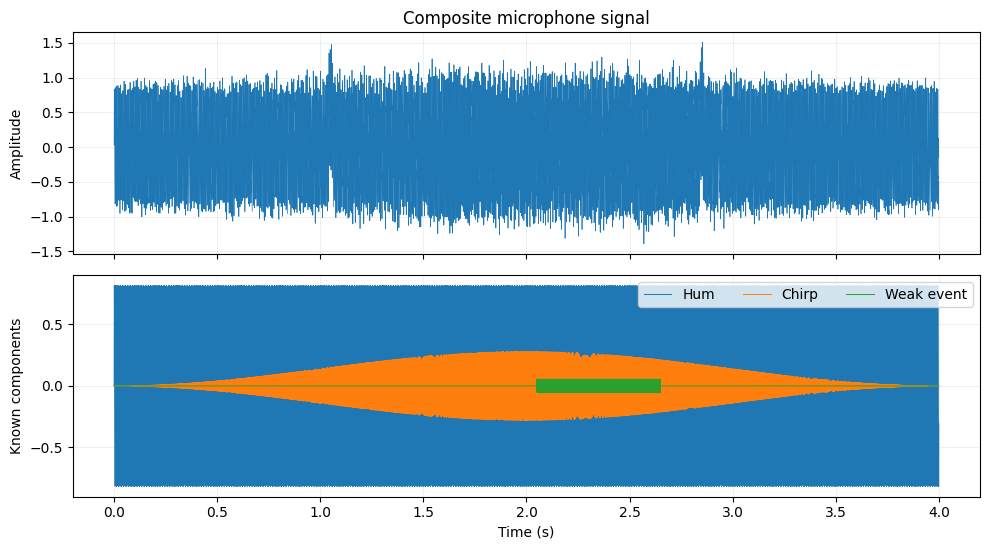

In [3]:
fig, ax = plt.subplots(2,1,figsize=(10,5.6),sharex=True)
ax[0].plot(T,audio,lw=.5);ax[0].set(ylabel='Amplitude',title='Composite microphone signal')
ax[1].plot(T,hum,lw=.7,label='Hum');ax[1].plot(T,chirp_part,lw=.7,label='Chirp')
ax[1].plot(T,weak_tone,lw=.7,label='Weak event');ax[1].set(xlabel='Time (s)',ylabel='Known components');ax[1].legend(ncol=3)
plt.tight_layout();plt.show()

**Interpret:** The waveform retains timing and amplitude, but overlapping oscillations are hard to separate by eye. The lower panel is *ground truth for learning*, not a processing step students normally possess.

**Ask:** If the weak tone amplitude is small, does that make it scientifically unimportant?

## Experiment 2 — LIVE | FFT versus windowed Fourier analysis (STFT)
The FFT of the whole recording summarizes *which frequencies occurred*. STFT computes spectra for overlapping windows and retains approximately *when* each frequency occurred.

**Predict:** Will the moving-frequency chirp be distinguishable from a stationary 170 Hz hum in both plots?

**Controls:** change `N_PER_SEG` between 128, 256 and 512; keep `N_OVERLAP < N_PER_SEG`.

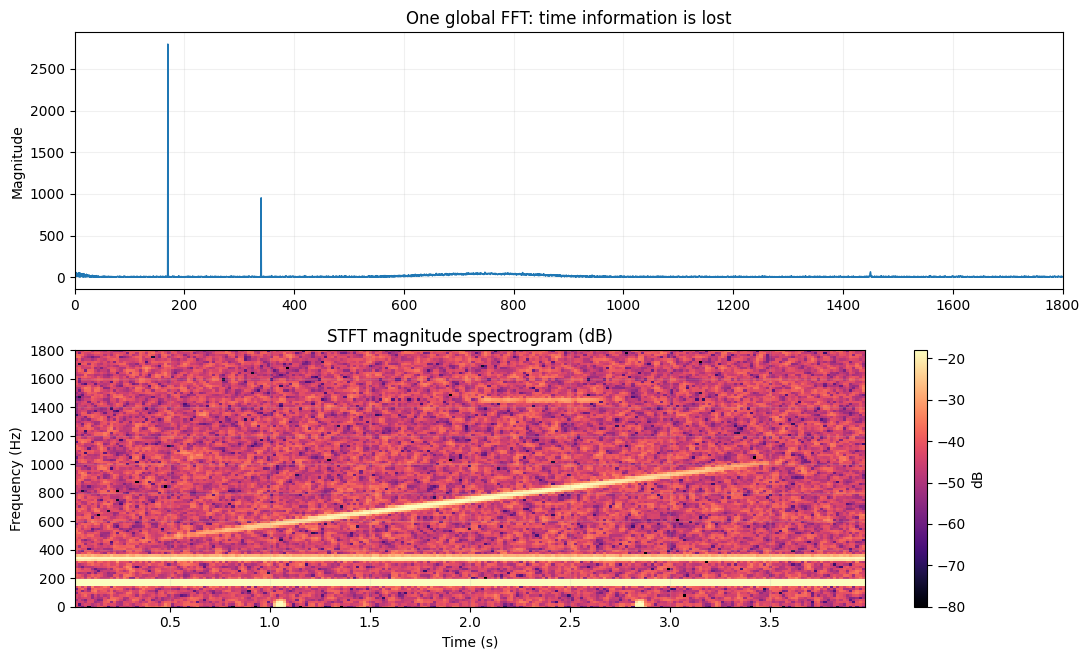

Spectrogram shape (frequency bins × time frames): (129, 247); hop = 64 samples


In [4]:
fft_freq = np.fft.rfftfreq(audio.size, d=1/FS)
fft_mag = np.abs(np.fft.rfft(audio * np.hanning(audio.size)))
N_PER_SEG, N_OVERLAP = 256, 192
f, frame_t, Z = signal.stft(audio, fs=FS, window='hann', nperseg=N_PER_SEG,
                          noverlap=N_OVERLAP, boundary=None, padded=False)
S = np.abs(Z)
S_DB = 20*np.log10(S + 1e-6)
fig, axes = plt.subplots(2,1,figsize=(11,6.7))
axes[0].plot(fft_freq,fft_mag,lw=1);axes[0].set(xlim=(0,1800),ylabel='Magnitude',title='One global FFT: time information is lost')
im=axes[1].pcolormesh(frame_t,f,S_DB,shading='auto',cmap='magma',vmin=-80,vmax=-18)
axes[1].set(ylim=(0,1800),xlabel='Time (s)',ylabel='Frequency (Hz)',title='STFT magnitude spectrogram (dB)')
fig.colorbar(im,ax=axes[1],label='dB');plt.tight_layout();plt.show()
print(f'Spectrogram shape (frequency bins × time frames): {S.shape}; hop = {N_PER_SEG-N_OVERLAP} samples')

**Interpret:** The hum appears as horizontal bands; the chirp traces a slanted line; impulses produce short broadband columns. The weak high-frequency event may be hard to notice at this color scale.

**Check:** `N_PER_SEG` controls a time/frequency resolution trade-off. More overlap adds *more displayed frames* but does not automatically create more independent information.

### LIVE mini-investigation | Window length and leakage
Compare 128 versus 512 samples in the two spectrograms. A larger window typically improves frequency resolution for stationary tones while smearing rapid temporal changes. Windowing (Hann) reduces spectral leakage relative to a rectangular window, at the cost of a broader main lobe.

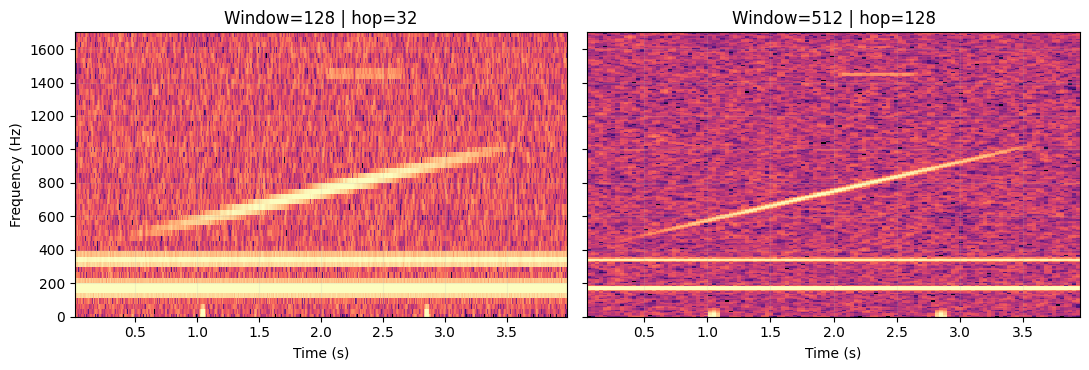

In [5]:
fig,axs=plt.subplots(1,2,figsize=(11,3.8),sharey=True)
for ax,win in zip(axs,[128,512]):
    ff,tt,zz=signal.stft(audio,fs=FS,nperseg=win,noverlap=3*win//4,boundary=None,padded=False)
    ax.pcolormesh(tt,ff,20*np.log10(np.abs(zz)+1e-6),shading='auto',cmap='magma',vmin=-80,vmax=-18)
    ax.set(ylim=(0,1700),title=f'Window={win} | hop={win//4}',xlabel='Time (s)')
axs[0].set_ylabel('Frequency (Hz)');plt.tight_layout();plt.show()

## Experiment 3 — LIVE | Hand-designed features from signal frames
The spectrum can be represented by physically interpretable measurements. Here we compute frame-wise **RMS**, **spectral centroid**, **spectral bandwidth**, and **positive spectral flux**. This is a bridge from traditional signal processing (fixed feature maps) to data-learned representations (PCA).

**Predict:** Which feature should react most clearly to an impulse? What does a spectral centroid measure?

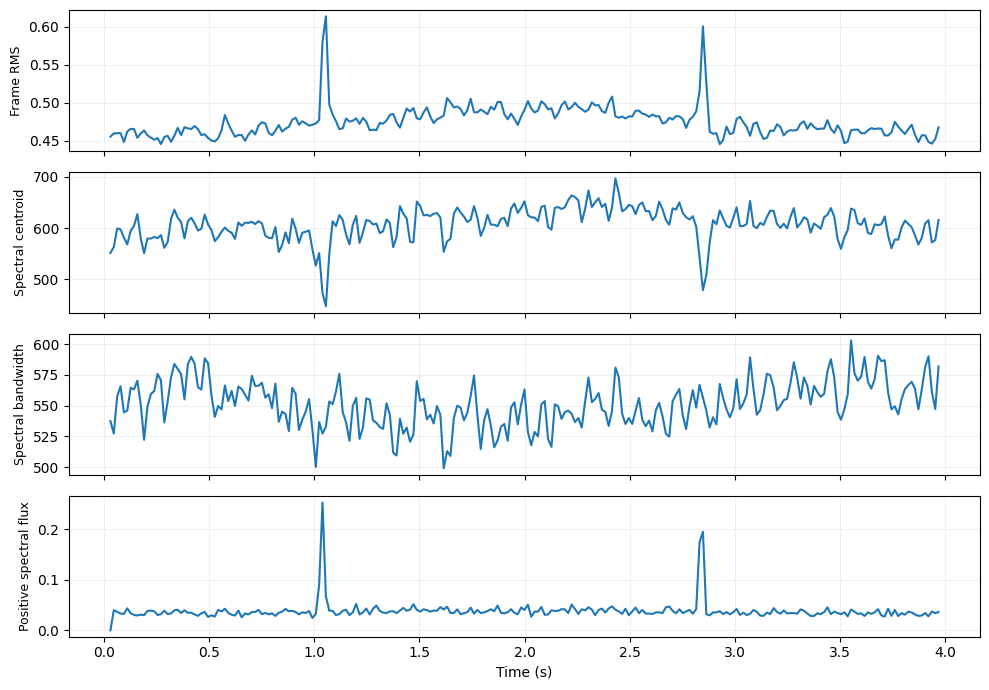

Feature matrix (frames × handcrafted features): (247, 4)


In [6]:
# Each column of S corresponds to one time frame.
frame_energy = np.sum(S**2,axis=0)
frame_rms = np.sqrt(frame_energy+1e-12)
centroid = (f[:,None]*S).sum(axis=0)/(S.sum(axis=0)+1e-12)
bandwidth = np.sqrt(( ((f[:,None]-centroid[None,:])**2)*S).sum(axis=0)/(S.sum(axis=0)+1e-12))
positive_diff = np.maximum(np.diff(S,axis=1,prepend=S[:,[0]]),0)
flux = np.sqrt((positive_diff**2).sum(axis=0))
features = np.column_stack([frame_rms,centroid,bandwidth,flux])
fig,axes=plt.subplots(4,1,figsize=(10,7),sharex=True)
for ax,name,values in zip(axes,['Frame RMS','Spectral centroid','Spectral bandwidth','Positive spectral flux'],features.T):
    ax.plot(frame_t,values);ax.set_ylabel(name,fontsize=9)
axes[-1].set_xlabel('Time (s)');plt.tight_layout();plt.show()
print('Feature matrix (frames × handcrafted features):', features.shape)

**Interpret:** A feature can summarize an aspect of the signal and still discard details. Flux is sensitive to *changes between adjacent frames*; centroid is a magnitude-weighted average frequency, not the strongest spectral peak.

**Ask:** Would these four features be enough to reconstruct the waveform? No: a compact descriptor is not generally invertible.

## Experiment 3B — LIVE | Covariance geometry in audio features
**Lecture link:** covariance → eigenstructure → PCA. Choose two continuous, physically meaningful frame features (spectral centroid and spectral bandwidth), then standardize each axis **only for this geometry demo**. Standardization makes both axes comparable; it is a choice, not an automatic requirement for PCA.

**Predict:** If the two descriptors co-vary, will the principal direction align with either raw feature axis? Compare projected spread along PC1 versus PC2.

**Note:** These are STFT frames of *one* recording with overlap; this is a within-recording illustration, not an independent-sample confidence interval.

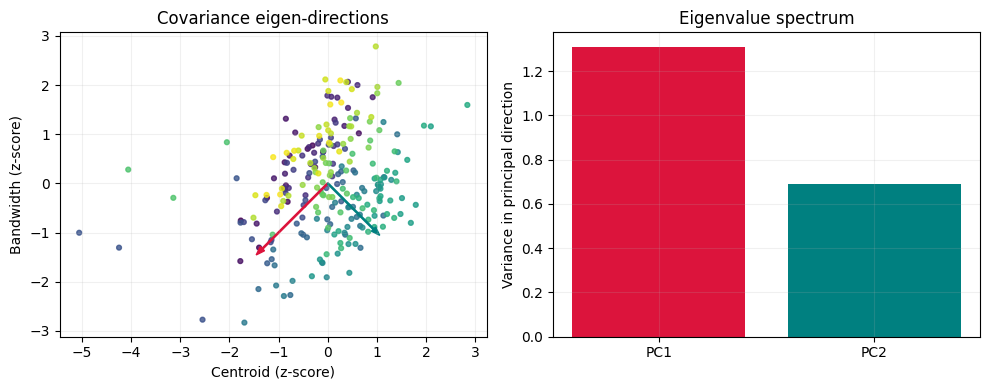

2×2 covariance:
[[1.    0.309]
 [0.309 1.   ]]
eigenvalues:
[1.309 0.691]
Fraction retained with PC1: 0.655


In [7]:
# Two-dimensional example from the SAME audio: centroid and bandwidth.
F2 = np.column_stack([centroid, bandwidth])
F2z = (F2 - F2.mean(axis=0)) / F2.std(axis=0)
C2 = (F2z.T @ F2z) / len(F2z)  # covariance convention 1/N
lam2, Q2 = np.linalg.eigh(C2)
order = np.argsort(lam2)[::-1]
lam2, Q2 = lam2[order], Q2[:, order]
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].scatter(F2z[:,0], F2z[:,1], c=frame_t, cmap='viridis', s=12, alpha=.8)
center = F2z.mean(axis=0)
for j, color in enumerate(['crimson','teal']):
    vec = Q2[:,j] * 1.8*np.sqrt(lam2[j])
    axs[0].arrow(center[0],center[1],vec[0],vec[1],head_width=.12,color=color,width=.025,length_includes_head=True)
axs[0].set(xlabel='Centroid (z-score)',ylabel='Bandwidth (z-score)',title='Covariance eigen-directions')
axs[0].axis('equal')
axs[1].bar(['PC1','PC2'],lam2,color=['crimson','teal'])
axs[1].set(ylabel='Variance in principal direction',title='Eigenvalue spectrum')
plt.tight_layout(); plt.show()
print('2×2 covariance:',np.round(C2,3),'eigenvalues:',np.round(lam2,3),sep='\n')
print('Fraction retained with PC1:',round(lam2[0]/lam2.sum(),3))

**Interpret:** A covariance eigenvector is an orthogonal direction; its eigenvalue is the variance after projection onto that direction. For this standardized example, the total variance is approximately 2. Changing the feature units or scaling changes the covariance geometry.

**Ask:** Why is a direction's sign irrelevant? What changes if the features are nearly uncorrelated?

## Experiment 4 — LIVE | PCA as a learned coordinate system for spectral frames
Each time frame becomes a high-dimensional vector (one feature per frequency bin). We apply PCA to **log-magnitude spectra** and visualize the first two coordinates. This is a different dataset and objective from Homework 2.

**Key warning:** PCA is learned from data; our time frames are correlated because STFT windows overlap. We are exploring a recording, *not* claiming statistical generalization to unseen recordings.

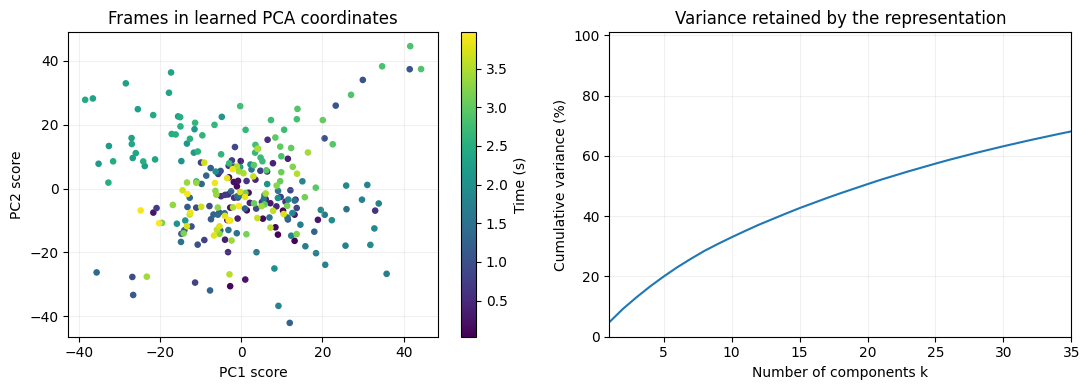

Explained variance by first 5 PCs: [0.049 0.044 0.038 0.036 0.033]


In [8]:
# Feature normalization across time frames: center per frequency bin.
X = S_DB.T                 # frames × frequency bins
X_mean = X.mean(axis=0)
Xc = X - X_mean
pca = PCA(svd_solver='full')
coords = pca.fit_transform(X)
evr = pca.explained_variance_ratio_
fig,ax=plt.subplots(1,2,figsize=(11,4.0))
p=ax[0].scatter(coords[:,0],coords[:,1],c=frame_t,cmap='viridis',s=14)
ax[0].set(xlabel='PC1 score',ylabel='PC2 score',title='Frames in learned PCA coordinates')
fig.colorbar(p,ax=ax[0],label='Time (s)')
ax[1].plot(np.arange(1,len(evr)+1),100*np.cumsum(evr));ax[1].set(xlim=(1,35),ylim=(0,101),xlabel='Number of components k',ylabel='Cumulative variance (%)',title='Variance retained by the representation')
plt.tight_layout();plt.show()
print('Explained variance by first 5 PCs:',np.round(evr[:5],3))

**Interpret:** PCA is not inherently a denoiser or a classifier. Its scores are a learned coordinate system capturing dominant differences among frames. The color trend suggests how the spectral content evolves over time.

**Ask:** A high explained-variance ratio answers *which* question? It quantifies retained variance in these chosen input features, not fidelity to the original complex audio signal.

### SVD connection and rank truncation (LIVE)
For the centered matrix `Xc` with **frames as rows**, `Xc = U Σ Vᵀ`. Right singular vectors (rows of `Vᵀ`) span the frequency-feature directions of PCA. The best rank-`k` approximation minimizes Frobenius error on the same centered matrix.

Here we show reconstruction of **log-magnitude spectra**, not restoration of audio waveforms. Discarded phase and the log transform matter.

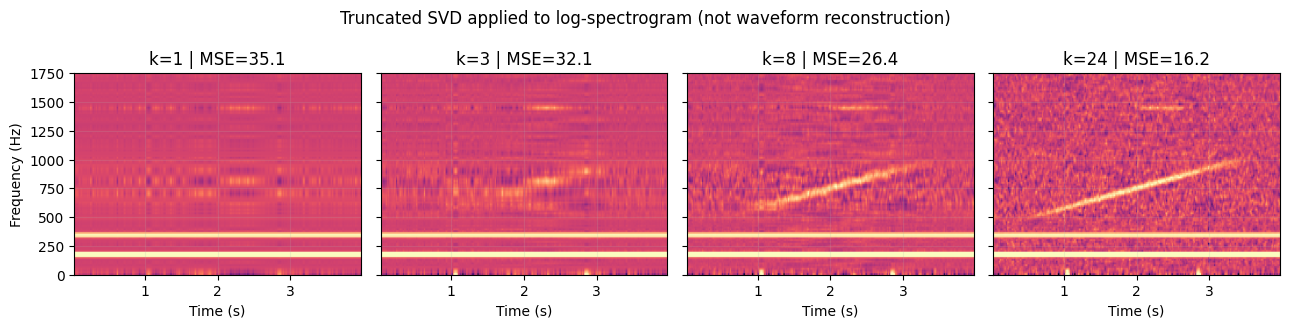

Max difference in leading explained variances, PCA vs SVD: 1.3877787807814457e-17


In [9]:
U,s,Vt=np.linalg.svd(Xc,full_matrices=False)
fig,axs=plt.subplots(1,4,figsize=(13,3.3),sharex=True,sharey=True)
for ax,k in zip(axs,[1,3,8,24]):
    Xhat=(U[:,:k]*s[:k])@Vt[:k,:]+X_mean
    error=np.mean((X-Xhat)**2)
    ax.imshow(Xhat.T,aspect='auto',origin='lower',extent=[frame_t[0],frame_t[-1],f[0],f[-1]],cmap='magma',vmin=-80,vmax=-18)
    ax.set(ylim=(0,1750),xlabel='Time (s)',title=f'k={k} | MSE={error:.1f}')
axs[0].set_ylabel('Frequency (Hz)');fig.suptitle('Truncated SVD applied to log-spectrogram (not waveform reconstruction)')
plt.tight_layout();plt.show()
print('Max difference in leading explained variances, PCA vs SVD:',np.max(np.abs(evr[:10]-s[:10]**2/np.sum(s**2))))

**Interpret:** As `k` rises, the matrix approximation becomes closer to the input log-spectrogram and the *training matrix* Frobenius error cannot increase. However, a faint transient may only reappear at larger `k`.

**Boundary with homework:** We intentionally do **not** derive or implement `pca_evd`, `pca_svd`, regularized sensor covariance, principal-angle Monte Carlo, or Eigenfaces here.

## Experiment 4C — LIVE | Preprocessing and sample sensitivity
**Lecture link:** the dominant subspace depends on what is measured and how features are scaled. We compare (a) raw audio-frame descriptors and (b) standardized descriptors, then estimate the leading direction from different subsets of frames.

This is **not** the homework's multi-sensor Monte Carlo, subspace-angle evaluation or covariance-shrinkage task. It is a visual sensitivity check using an unrelated signal representation.

**Predict:** Which feature dominates PCA without scaling? Why does training on fewer frames make the estimated direction less stable?

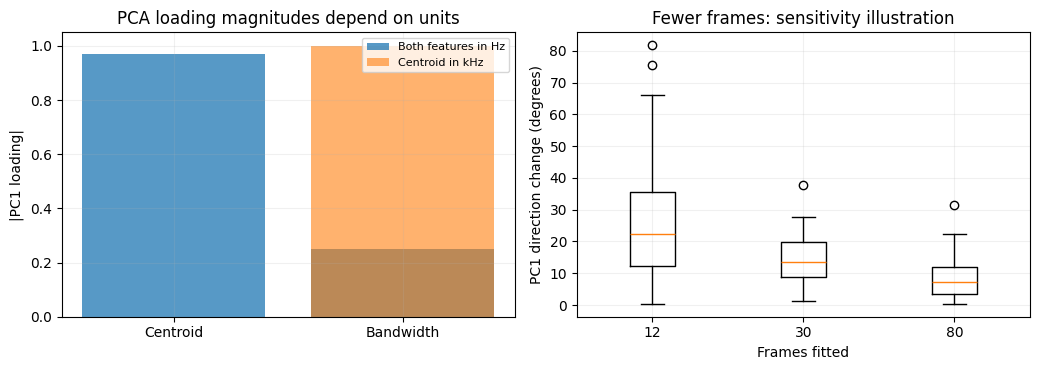

In [10]:
from sklearn.preprocessing import StandardScaler
F4=features.copy()
raw2=F4[:,[1,2]]    # centroid and bandwidth, both in Hz
scaled2=StandardScaler().fit_transform(F4[:,[1,2]])
# Give one variable a deliberate change of engineering units to expose scale sensitivity.
unit_changed=raw2.copy();unit_changed[:,0]*=0.001  # centroid now in kHz while bandwidth remains Hz
p1=PCA(n_components=1).fit(raw2)
p2=PCA(n_components=1).fit(unit_changed)
fig,ax=plt.subplots(1,2,figsize=(10.5,3.8))
ax[0].bar(['Centroid','Bandwidth'],np.abs(p1.components_[0]),label='Both features in Hz',alpha=.75)
ax[0].bar(['Centroid','Bandwidth'],np.abs(p2.components_[0]),label='Centroid in kHz',alpha=.6)
ax[0].set(title='PCA loading magnitudes depend on units',ylabel='|PC1 loading|');ax[0].legend(fontsize=8)
# Simple independent draws of frame indices from the SAME recording: only illustrates instability.
rg3=np.random.default_rng(SEED+88)
base=PCA(n_components=1).fit(scaled2).components_[0]
results={}
for nframes in [12,30,80]:
    vals=[]
    for _ in range(35):
        idx=rg3.choice(len(scaled2),size=nframes,replace=False)
        cand=PCA(n_components=1).fit(scaled2[idx]).components_[0]
        vals.append(np.degrees(np.arccos(np.clip(abs(cand@base),0,1))))
    results[nframes]=vals
ax[1].boxplot(list(results.values()),tick_labels=[str(x) for x in results]);ax[1].set(xlabel='Frames fitted',ylabel='PC1 direction change (degrees)',title='Fewer frames: sensitivity illustration')
plt.tight_layout();plt.show()

**Interpret:** Changing engineering units can rotate a PCA direction because ordinary PCA operates on variances measured in those units. The resampling panel shows variability of estimates across frame subsets; overlapping STFT frames mean this should **not** be treated as a formal independent Monte Carlo study.

**Ask:** Is standardization always desirable? No; it depends on whether the units and physical amplitudes are meaningful to the task.

## Experiment 5 — LIVE | Is the representation sufficient for the question we care about?
A recording may contain a weak high-frequency alarm during a short interval. Its energy is small compared with the hum and chirp. We do not use supervised labels to fit PCA: the event interval is revealed only to **inspect** how a learned representation retains a weak feature.

**Proxy measurement:** integrated energy in a narrow frequency band around the event's 1450 Hz tone. Compare it before and after truncated reconstruction. This is not a classifier and not Homework 2's nuisance/label construction.

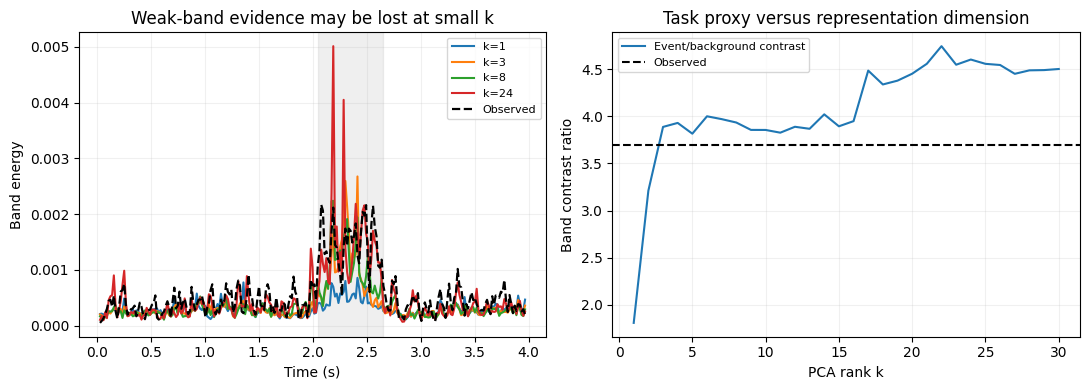

In [11]:
target=(f>=1400)&(f<=1500)
# Work in the same log-magnitude feature coordinates; convert back to nonnegative magnitude.
def band_energy(db_frames):
    magnitudes=10**(db_frames/20)
    return (magnitudes[:,target]**2).sum(axis=1)
ref=band_energy(X)
frame_event=(frame_t>=2.05)&(frame_t<2.65)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for k in [1,3,8,24]:
    Xhat=(U[:,:k]*s[:k])@Vt[:k]+X_mean
    eng=band_energy(Xhat)
    axes[0].plot(frame_t,eng,label=f'k={k}')
axes[0].plot(frame_t,ref,c='black',ls='--',lw=1.6,label='Observed')
axes[0].axvspan(2.05,2.65,color='gray',alpha=.12);axes[0].legend(fontsize=8)
axes[0].set(xlabel='Time (s)',ylabel='Band energy',title='Weak-band evidence may be lost at small k')
ratios=[]
for k in range(1,31):
    xh=(U[:,:k]*s[:k])@Vt[:k]+X_mean
    e=band_energy(xh)
    ratios.append((e[frame_event].mean()+1e-12)/(e[~frame_event].mean()+1e-12))
axes[1].plot(range(1,31),ratios,label='Event/background contrast');axes[1].axhline((ref[frame_event].mean()+1e-12)/(ref[~frame_event].mean()+1e-12),ls='--',c='black',label='Observed')
axes[1].set(xlabel='PCA rank k',ylabel='Band contrast ratio',title='Task proxy versus representation dimension');axes[1].legend(fontsize=8)
plt.tight_layout();plt.show()

**Interpret with care:** If the weak-band contrast is suppressed by a low-rank representation, we have a concrete example of **task mismatch**: high-variance structure can dominate while a small but operationally important event gets muted. If a curve is nonmonotonic, that is allowed: only Frobenius reconstruction error is guaranteed to decrease with `k`, not this external contrast metric.

**Discussion:** Does selecting `k` using observed event labels turn an unsupervised representation into a task-selected pipeline? Yes; evaluation must keep selection separate from final testing.

## Experiment 6 — LIVE / SHORT | PCA is not whitening
**Lecture link:** PCA rotates into uncorrelated coordinates; PCA whitening also divides each principal score by the square root of its variance. On our two audio descriptors, compare the score covariances before and after regularized whitening.

**Predict:** Which transformation makes covariance diagonal? Which also makes the diagonal *approximately* one? With `eps>0`, it is not exactly one.

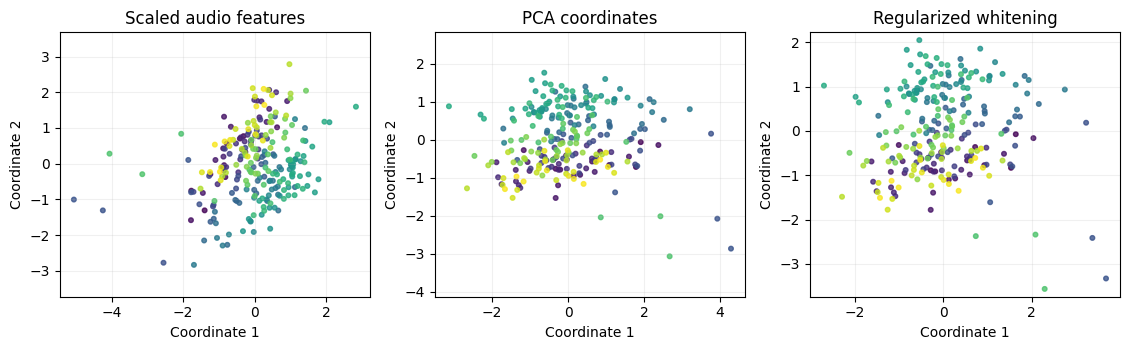

Covariance of PCA coordinates:
 [[1.309 0.   ]
 [0.    0.691]]
Covariance after regularized whitening:
 [[0.963 0.   ]
 [0.    0.932]]


In [12]:
# Reuse C2 eigensystem and the SAME 2D standardized audio features.
P2 = F2z @ Q2
EPS_WHITE = .05
Pw = P2 / np.sqrt(lam2 + EPS_WHITE)
fig, axes=plt.subplots(1,3,figsize=(11.4,3.6),sharex=False,sharey=False)
for ax,dat,title in zip(axes,[F2z,P2,Pw],['Scaled audio features','PCA coordinates','Regularized whitening']):
    ax.scatter(dat[:,0],dat[:,1],s=11,c=frame_t,cmap='viridis',alpha=.8)
    ax.set(title=title,xlabel='Coordinate 1',ylabel='Coordinate 2');ax.axis('equal')
plt.tight_layout();plt.show()
print('Covariance of PCA coordinates:\n',np.round(P2.T@P2/len(P2),3))
print('Covariance after regularized whitening:\n',np.round(Pw.T@Pw/len(Pw),3))

**Interpret:** PCA removes second-order cross-covariance; whitening changes the scale along each principal direction. When a small eigenvalue is divided by a small number, sensor noise can be amplified. Regularization tempers this gain but no longer gives an exact identity covariance.

**Important:** zero covariance does not imply statistical independence, except under jointly Gaussian assumptions.

## Synthesis
- **Raw waveform:** where amplitude varies.
- **Global FFT:** which frequencies occur in total, but not *when*.
- **STFT:** frequency composition across time; it depends on window and hop choices.
- **Handcrafted descriptors:** interpretable but incomplete summaries.
- **PCA/SVD:** learned linear coordinates, optimal for variance / Frobenius reconstruction under its assumptions.
- **Task relevance:** retained variance need not retain a weak alarm.

**Exit questions:** (1) What does increasing STFT overlap actually change? (2) Which SVD vectors are PCA feature directions for rows-as-samples data? (3) Why might a weak event disappear from the first PCs? (4) Where would you fit normalization parameters in a multi-recording train/test experiment?

# OPTIONAL / AFTER CLASS — extensions
The following activities are **not required for the 60-minute session** and are **not homework solutions**.

## OPTIONAL A | Whitening sensitivity: a follow-up
The live experiment above compares PCA and regularized whitening on two audio descriptors. For independent study, vary `EPS_WHITE` over `{0, 0.01, 0.1, 1.0}` and record the output covariance and the largest scaling factor. Explain the noise amplification risk; do not copy the homework’s implementation.

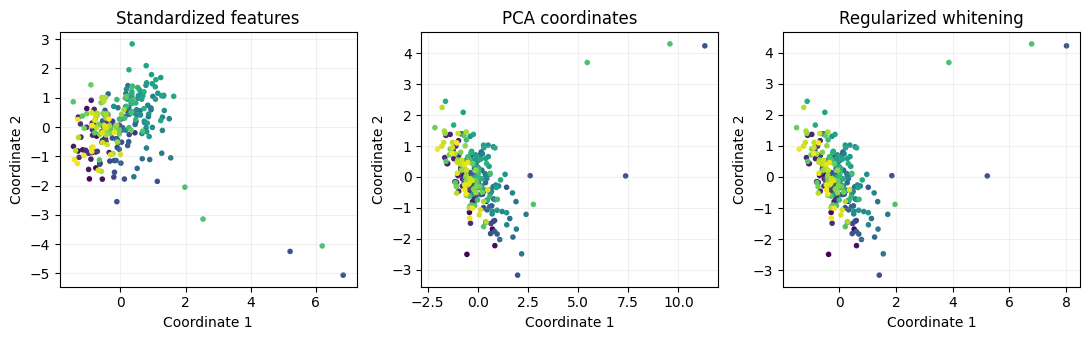

PCA variances: [1.954 0.972 0.805 0.269]
Whitened variances: [0.981 0.966 0.96  0.896]


In [13]:
feat_train=features.copy()
standardized=StandardScaler().fit_transform(feat_train)
pc=PCA().fit(standardized)
P=pc.transform(standardized)
eps=0.03
white=P/np.sqrt(pc.explained_variance_[None,:]+eps)
fig,axs=plt.subplots(1,3,figsize=(11,3.5))
for ax,data,title in zip(axs,[standardized,P,white],['Standardized features','PCA coordinates','Regularized whitening']):
    ax.scatter(data[:,0],data[:,1],c=frame_t,cmap='viridis',s=9)
    ax.set(title=title,xlabel='Coordinate 1',ylabel='Coordinate 2')
plt.tight_layout();plt.show()
print('PCA variances:',np.round(np.var(P,axis=0),3))
print('Whitened variances:',np.round(np.var(white,axis=0),3))

**Question:** Why are whitening variances slightly below one? We divided by `sqrt(lambda + eps)`, not exactly `sqrt(lambda)`. Also the sample covariance convention (`N` vs `N-1`) changes the displayed numerical scale.

## OPTIONAL B | Two microphones: a shared acoustic source and CCA
**Lecture link:** PCA describes structure *within* one view; CCA seeks correlated linear combinations *across* two aligned views. Each microphone records a shared signal plus distinct interference and sensor noise. For transparency we use short-time log-spectral feature vectors at aligned time frames.

This is an extension, not part of the core 60-minute delivery. It does **not** implement the homework's two-sensor hidden-factor CCA exercise or its requested solver. Here a library estimator visualizes the cross-view idea.

**Predict:** Should the strongest-variance dimension from microphone A necessarily be the most correlated with microphone B?

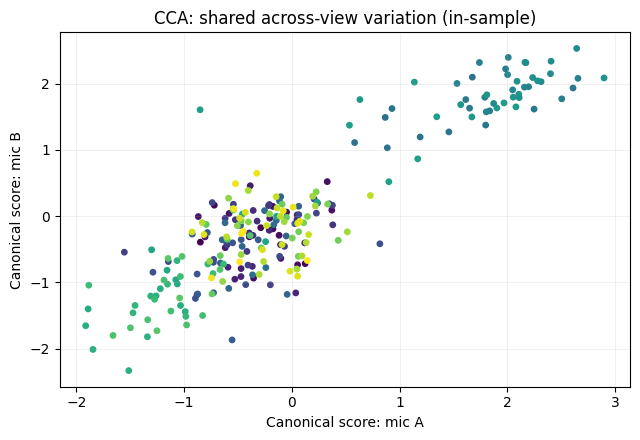

Canonical correlation (in-sample): 0.898


In [14]:
from sklearn.cross_decomposition import CCA
# Two synchronized recordings with distinct interference and noise.
rg2 = np.random.default_rng(SEED+71)
mic_a = audio + 0.28*np.sin(2*np.pi*800*T) + 0.12*rg2.standard_normal(T.size)
mic_b = 0.88*audio + 0.35*np.sin(2*np.pi*600*T + .7) + 0.12*rg2.standard_normal(T.size)
def stft_feature_matrix(wave):
    ff,tt,zz=signal.stft(wave,fs=FS,window='hann',nperseg=N_PER_SEG,noverlap=N_OVERLAP,boundary=None,padded=False)
    mag=np.abs(zz)
    # Aggregate frequencies into broad bands to avoid a high-dimensional and ill-conditioned CCA.
    edges=np.linspace(0,1600,13)
    return np.stack([np.log1p(1e3*mag[(ff>=a)&(ff<b)].mean(axis=0)) for a,b in zip(edges[:-1],edges[1:])],axis=1)
A_view=stft_feature_matrix(mic_a); B_view=stft_feature_matrix(mic_b)
za=StandardScaler().fit_transform(A_view); zb=StandardScaler().fit_transform(B_view)
cca_demo=CCA(n_components=1,max_iter=1000,scale=False)
ca,cb=cca_demo.fit_transform(za,zb)
# The correlation is descriptive on the SAME frames used to fit CCA: not generalization.
fig,ax=plt.subplots(figsize=(6.5,4.5))
ax.scatter(ca[:,0],cb[:,0],s=15,c=frame_t,cmap='viridis')
ax.set(xlabel='Canonical score: mic A',ylabel='Canonical score: mic B',title='CCA: shared across-view variation (in-sample)')
plt.tight_layout();plt.show()
print('Canonical correlation (in-sample):',round(np.corrcoef(ca[:,0],cb[:,0])[0,1],3))

**Interpret:** High in-sample canonical correlation suggests there is a pair of directions that co-vary across the two views; it does not prove physical source separation, causality or out-of-sample reliability. Two separate PCA fits instead optimize variance within each channel.

**Challenge:** Change the strength of microphone-specific tones. Why might PCA focus on an interference that CCA tends to discount? Use a held-out recording for any transfer claim.

## Optional C | From the spectrogram to NMF (conceptual bridge, not a worked solution)
A magnitude spectrogram is nonnegative, so it is a natural object for a *parts-based* factorization `V ≈ WH` with nonnegative factors. In audio applications, columns of `W` can be interpreted as spectral templates and rows of `H` as time-varying activations.

This clinic **does not** implement multiplicative-update NMF or evaluate rank choice; those are explicitly left to the Homework 2 bonus investigation. Contrast the nonnegative constraint with SVD's signed orthogonal bases.

## Optional D | Robustness and research questions
1. Replace white noise with impulsive or narrowband interference. Which plots change most?
2. Shift the target tone from 1450 Hz toward the chirp. When does the band-energy proxy become unreliable?
3. Add a second synthetic recording with a different sensor gain; learn preprocessing only on one recording and discuss domain shift.
4. Compare Hann and rectangular windows at fixed length. When is leakage worst?
5. Explain why a log-spectrogram is not a linear representation of the raw waveform.

For each investigation report **what was changed, what was held fixed, and what can legitimately be concluded**.